In [1]:
import torch
import numpy as np
import random
import os

def set_seed(seed=42):
    random.seed(seed) #Sets the seed for Python’s built-in random module
    np.random.seed(seed) #Sets the seed for NumPy.
    torch.manual_seed(seed) #Sets the seed for PyTorch operations on the CPU.
    torch.cuda.manual_seed_all(seed)  # Sets the seed for PyTorch operations across all available GPUs (CUDA).
    os.environ['PYTHONHASHSEED'] = str(seed) #Fixes Python's internal string and object hashing.

set_seed(42)

In [2]:
#Input Dataset

import pandas as pd

df = pd.read_csv(r"C:\Project\Old_Project\Code\DataCoSupplyChainDataset.csv", encoding='latin-1')   

In [3]:
import numpy as np
import pandas as pd

def compute_imbalance (target):

    #Step 1: Counting occurences of each unique class in the target variable
    counts = target.value_counts()

    #Step 2: converting counts to probabilities
    total = counts.sum()
    probability=counts / total

    #Step 3: Computing Shannon Entropy
    H = 0
    for cls, prob in probability.items(): #Getting both the classes together at a pass
        H -= prob * np.log(prob)

    k = len(counts) #Number of unique classes

    #Step 4: Computing Imbalance Ratio
    B = H / np.log(k)

    return B

def compute_diversity (df_subset):

    H_list = [] 

    for feat in df_subset.columns:
        counts = df_subset[feat].value_counts()
        total = counts.sum()
        probability = counts / total

        # Calculating Shanon Entropy for all the values 
        H_feat=0
        for val, prob in probability.items():
            H_feat -= prob * np.log(prob)

        H_list.append(H_feat)

    #Average across all features for a silo
    diversity = sum(H_list) / len(H_list)

    return diversity


#Excluding columns based on which imabalnce and diversity will be calculated
exclude_from_diversity = ['Late_delivery_risk', 'Order Region', 'Customer Id']
diversity_cols         = [c for c in df.columns if c not in exclude_from_diversity]

# Finding shared buyers (Customers who received orders through multiple regions)
buyer_market     = df.groupby('Customer Id')['Order Region'].nunique()
shared_buyer_ids = buyer_market[buyer_market > 1].index

#Preparing Silos
silos = df['Order Region'].dropna().unique() #.unique() does not show all 180k rows of data in the table

rows = []

for silo in silos: #Use sorted(silos) if want to sort the silos alphabetically
    subset_as_per_present_silo = df [df['Order Region'] == silo]

    n_orders = len(subset_as_per_present_silo)
    n_buyers = subset_as_per_present_silo['Customer Id'].nunique()
    shared_buyers = subset_as_per_present_silo[subset_as_per_present_silo['Customer Id'].isin(shared_buyer_ids)]['Customer Id'].nunique()
    shared_rate = shared_buyers / n_buyers * 100

    on_time_rate = (subset_as_per_present_silo['Late_delivery_risk'] == 0).sum() / n_orders * 100
    delayed_rate = (subset_as_per_present_silo['Late_delivery_risk'] == 1).sum() / n_orders * 100

    imbalance = compute_imbalance(subset_as_per_present_silo['Late_delivery_risk'])
    diversity = compute_diversity(subset_as_per_present_silo[diversity_cols])

    rows.append({
        'Silo (Order Regions)': silo,
        'Orders' : n_orders,
        'Buyers' : n_buyers,
        'Shared Buyers (%)': f"{shared_buyers} ({shared_rate:.2f}%)",
        'On_Time_rate': f"{on_time_rate:.2f}%",
        'Delayed_rate': f"{delayed_rate:.2f}%",
        'Imbalance (B)'       : round(imbalance, 4),
        'Diversity (H)'       : round(diversity, 4)
    })

#Bottom Row for cumulative values across all silos
total_orders = len(df)
total_buyers        = df['Customer Id'].nunique()
shared_total = df[df['Customer Id'].isin(shared_buyer_ids)]['Customer Id'].nunique()
shared_rate_all     = shared_total / total_buyers * 100

rows.append({
    'Silo (Order Regions)': 'Total',
    'Orders' : total_orders,
    'Buyers' : total_buyers,
    'Shared Buyers (%)': f"{shared_total} ({shared_rate_all:.2f}%)",
    'On_Time_rate': f"{(df['Late_delivery_risk'] == 0).sum() / total_orders * 100:.2f}%",
    'Delayed_rate': f"{(df['Late_delivery_risk'] == 1).sum() / total_orders * 100:.2f}%",
    'Imbalance (B)'       : round(compute_imbalance(df['Late_delivery_risk']), 4),
    'Diversity (H)'       : round(compute_diversity(df[diversity_cols]), 4)
})

table1 = pd.DataFrame(rows)
print(table1.to_string(index=False))

Silo (Order Regions)  Orders  Buyers Shared Buyers (%) On_Time_rate Delayed_rate  Imbalance (B)  Diversity (H)
      Southeast Asia    9539    4101     2320 (56.57%)       44.47%       55.53%         0.9912         3.6272
          South Asia    7731    3153     2010 (63.75%)       43.73%       56.27%         0.9886         3.5879
             Oceania   10148    4042     2579 (63.81%)       45.98%       54.02%         0.9953         3.5770
        Eastern Asia    7280    3169     1830 (57.75%)       45.67%       54.33%         0.9946         3.6047
           West Asia    6009    1884     1867 (99.10%)       44.72%       55.28%         0.9919         3.3791
        West of USA     7993    2400     2363 (98.46%)       46.04%       53.96%         0.9955         3.4192
          US Center     5887    1783     1760 (98.71%)       44.76%       55.24%         0.9921         3.3970
         West Africa    3696    1164     1149 (98.71%)       47.16%       52.84%         0.9977         3.2784
 

In [4]:
#Data Cleaning

#Missing Values----------------------------
print("="*55)
print("Missing Values")
print("="*55)
missing_values = df.isnull().sum()
missing_pct = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_values, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]
print(missing_df)

#Duplicate Values----------------------------
print("="*55)
print("Duplicate Values")
print("="*55)
duplicates = df.duplicated().sum()
print(f"Fully duplicate rows: {duplicates}")

#Outliers------------------------------
print("\n" + "=" * 55)
print("OUTLIERS — IQR METHOD (numeric columns)")
print("=" * 55)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
outlier_summary = []
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    if n_outliers > 0:
        outlier_summary.append({'Column': col, 'Outlier Count': n_outliers,
                                 'Outlier %': round(n_outliers / len(df) * 100, 2),
                                 'Lower Bound': round(lower, 2),
                                 'Upper Bound': round(upper, 2)})
outlier_df = pd.DataFrame(outlier_summary).sort_values('Outlier %', ascending=False)
print(outlier_df.to_string(index=False))

#Inconsistent Values------------------------------
print("\n" + "=" * 55)
print("INCONSISTENT VALUES")
print("=" * 55)

# Parse dates
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'], errors='coerce')
df['shipping date (DateOrders)'] = pd.to_datetime(df['shipping date (DateOrders)'], errors='coerce')

# Check 1: Shipping date before order date (logistical impossibility)
mask_date = df['shipping date (DateOrders)'] < df['order date (DateOrders)']
print(f"Shipping date BEFORE order date: {mask_date.sum()} rows")

# Check 2: Scheduled shipment days < 0 (must be positive)
mask_days = df['Days for shipment (scheduled)'] < 0
print(f"Scheduled shipment days < 0:    {mask_days.sum()} rows")

# Check 3: Negative product price or quantity
mask_price = df['Product Price'] < 0
mask_qty   = df['Order Item Quantity'] <= 0
print(f"Negative product price:          {mask_price.sum()} rows")
print(f"Order quantity <= 0:             {mask_qty.sum()} rows")

# Check 4: Order item discount > 1 (discount rate should be 0–1)
mask_discount = df['Order Item Discount Rate'] > 1
print(f"Discount rate > 1:               {mask_discount.sum()} rows")

# Total inconsistent rows (union of all masks)
inconsistent_mask = mask_date | mask_days | mask_price | mask_qty | mask_discount
print(f"\nTotal inconsistent rows (union): {inconsistent_mask.sum()}")

Missing Values
                     Missing Count   Missing %
Customer Lname                   8    0.004432
Customer Zipcode                 3    0.001662
Order Zipcode               155679   86.239676
Product Description         180519  100.000000
Duplicate Values
Fully duplicate rows: 0

OUTLIERS — IQR METHOD (numeric columns)
                  Column  Outlier Count  Outlier %  Lower Bound  Upper Bound
       Benefit per order          18942      10.49       -79.70       151.50
  Order Profit Per Order          18942      10.49       -79.70       151.50
 Order Item Profit Ratio          17300       9.58        -0.34         0.78
     Order Item Discount           7537       4.18       -31.48        66.87
Order Item Product Price           2048       1.13      -174.99       424.98
           Product Price           2048       1.13      -174.99       424.98
      Sales per customer           1943       1.08      -110.15       461.93
        Order Item Total           1943       1.08  

In [5]:
#Checking if columns contain constant values
from sklearn.feature_selection import VarianceThreshold

print("--- VARIANCE PRUNING ---")
#Dropping columns which contains same or non unique values
constant_cols=[col for col in df.columns if df[col].nunique() <= 1]
print(f"Removing completely constant columns: {constant_cols}")
df_pruned = df.drop(columns=constant_cols)

#Checking which numerical features are nearly constant (Quasi-constant numerical features)
numerical_cols = df_pruned.select_dtypes(include=[np.number]).columns
selector = VarianceThreshold(threshold=0.01)  # Threshold for quasi-constant features
selector.fit(df_pruned[numerical_cols])

quasi_constant_cols = [col for col, keep in zip(numerical_cols, selector.get_support()) if not keep]
print(f"Removing quasi-constant numerical columns: {quasi_constant_cols}")
df_pruned = df_pruned.drop(columns=quasi_constant_cols)

--- VARIANCE PRUNING ---
Removing completely constant columns: ['Customer Email', 'Customer Password', 'Product Description', 'Product Status']
Removing quasi-constant numerical columns: ['Order Item Discount Rate']


In [6]:
#Dropping columns which will cause data leakage, missing values, zero variance, or are irrelevant for prediction
drop_cols = [
    # Post-fulfillment leakage
    'Days for shipping (real)',
    'Delivery Status',
    'Order Status',
    'shipping date (DateOrders)'

    # Missing values
    'Order Zipcode',                   # 86% missing
    'Product Description',             # 100% missing

    # Zero variance / irrelevant
    'Product Status',                  # zero variance
    'Product Image',                   # Won't help with prediction, just a URL
    'Customer Email', 
    'Customer Password', 
    'Product Description',
    'Order Item Discount Rate',

]

# Only drop columns that actually exist in df to avoid complexity during multiple runs
drop_cols = [c for c in drop_cols if c in df.columns]
df = df.drop(columns=drop_cols)
print(f"Dropped {len(drop_cols)} columns. Shape: {df.shape}")


print(f"\nRemaining columns:\n{df.columns.tolist()}")
print(f"Dropped {len(drop_cols)} columns. Shape: {df.shape}")

Dropped 10 columns. Shape: (180519, 44)

Remaining columns:
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Name', 'Product Price', 'shipping date (DateOrders)', 'Shipping Mode']
Dropped 10 columns. Shape: (180519, 44)


In [7]:
# Concatenate Customer Fname and Lname into Customer Name
df['Customer Name'] = df['Customer Fname'] + ' ' + df['Customer Lname']
df = df.drop(columns=['Customer Fname', 'Customer Lname'])
print(f"Created Customer Name. Shape: {df.shape}")

Created Customer Name. Shape: (180519, 43)


In [8]:
#Checking Data Types
print("\nData Types:\n", df.dtypes)


Data Types:
 Type                                        str
Days for shipment (scheduled)             int64
Benefit per order                       float64
Sales per customer                      float64
Late_delivery_risk                        int64
Category Id                               int64
Category Name                               str
Customer City                               str
Customer Country                            str
Customer Id                               int64
Customer Segment                            str
Customer State                              str
Customer Street                             str
Customer Zipcode                        float64
Department Id                             int64
Department Name                             str
Latitude                                float64
Longitude                               float64
Market                                      str
Order City                                  str
Order Country             

--- TRUE CONTINUOUS FEATURES FOR PEARSON ANALYSIS ---
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Price']


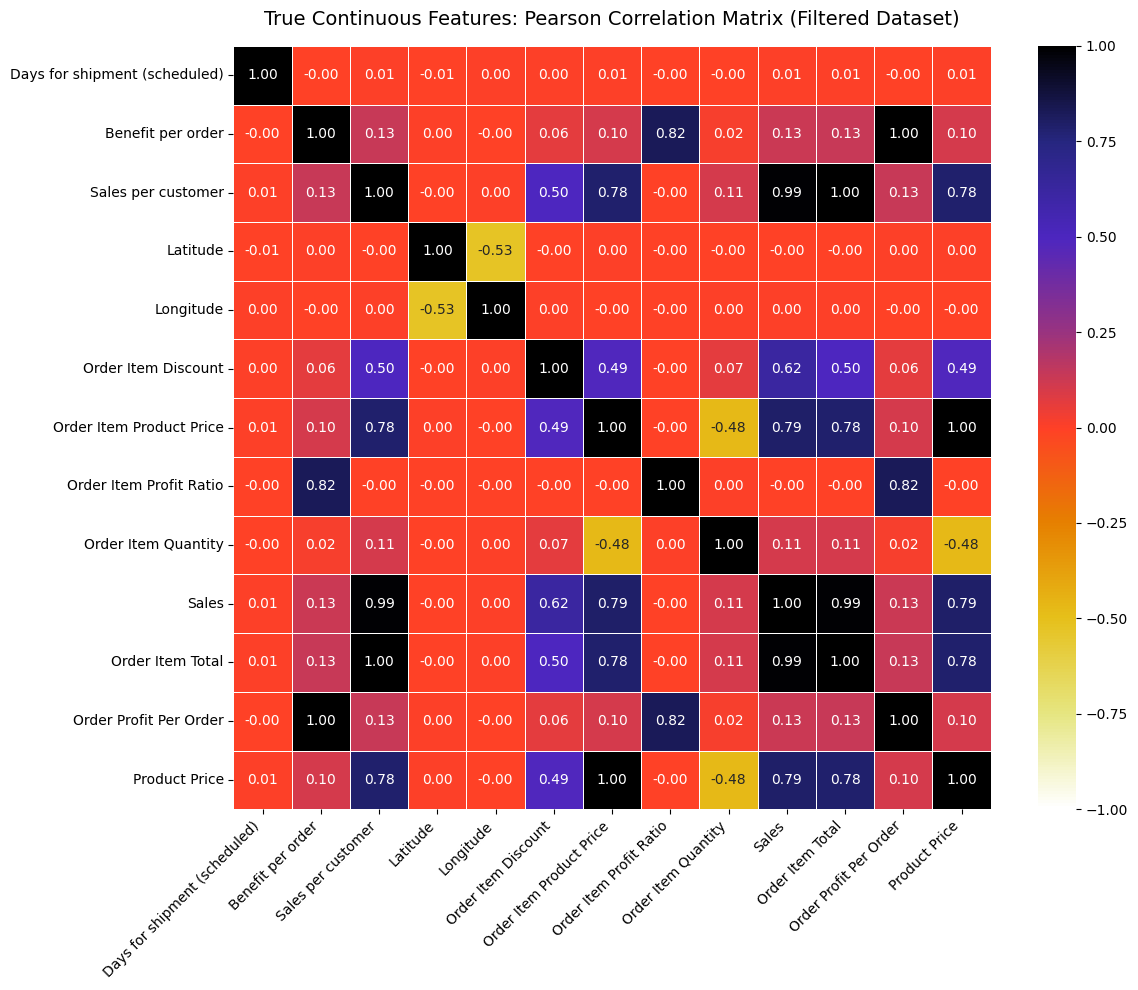

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

#Idetifying numerical columns before applying pearson correlation
all_numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

#Defining the categorical columns which are disguies as numerica
categorical_exclusions = [
    'Customer Id', 'Order Id', 'Category Id', 'Department Id', 
    'Order Customer Id', 'Order Item Cardprod Id', 'Order Item Id', 
    'Product Card Id', 'Product Category Id',
    'Customer Zipcode', 'Order Zipcode', 
    'Late_delivery_risk'  # Target feature
]

#Precautionary step to remove the columns that are only present
true_numeric_cols = [col for col in all_numeric_cols if col not in categorical_exclusions]

print("--- TRUE CONTINUOUS FEATURES FOR PEARSON ANALYSIS ---")
print(true_numeric_cols)

#Computing Pearson correlation matrix for true continuous features
if len(true_numeric_cols) > 1:
    pearson_matrix = df[true_numeric_cols].corr(method='pearson')
    
    # 6. Plot the Heatmap
    plt.figure(figsize=(12, 10))
    
    sns.heatmap(
        pearson_matrix, 
        annot=True,             # Display exact correlation coefficients
        cmap='CMRmap_r', 
        vmin=-1, vmax=1,        # Limit boundaries strictly to Pearson limits
        fmt=".2f", 
        linewidths=0.5
    )
    
    plt.title('True Continuous Features: Pearson Correlation Matrix (Filtered Dataset)', fontsize=14, pad=15)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    
    # Render the plot inline immediately
    plt.show()
else:
    print("\nNot enough continuous columns left after drops to build a correlation matrix.")

In [10]:
import pandas as pd
import numpy as np

print("--- SEQUENTIAL MULTICOLLINEARITY PRUNING ---")

#Compute the absolute Pearson correlation matrix for true numeric features
corr_matrix = df[true_numeric_cols].corr(method='pearson').abs() #Only taking the magnitude

threshold = 0.85
cols_to_drop = set()

# Checking the features sequentially to identify highly correlated pairs and flagging one of them for removal
for i in range(len(corr_matrix.columns)):
    col_name = corr_matrix.columns[i]
    
    # If this column was already flagged to be dropped, skip it
    if col_name in cols_to_drop:
        continue
        
    # Check all subsequent columns to see if they are highly correlated with this one
    for j in range(i + 1, len(corr_matrix.columns)):
        other_col = corr_matrix.columns[j]
        
        if corr_matrix.iloc[i, j] >= threshold:
            print(f"-> Highly correlated: '{col_name}' and '{other_col}' (r = {corr_matrix.iloc[i, j]:.2f}). Flagging '{other_col}' for removal.")
            cols_to_drop.add(other_col)

# Dropping redundant features based on the identified highly correlated pairs
drop_list = list(cols_to_drop)
df_no_multicollinearity = df.drop(columns=drop_list)

print("\n--- PRUNING SUMMARY ---")
print(f"Dropped features: {drop_list}")
remaining_numerics = [c for c in true_numeric_cols if c not in cols_to_drop]
print(f"Remaining true numeric features: {remaining_numerics}")

--- SEQUENTIAL MULTICOLLINEARITY PRUNING ---
-> Highly correlated: 'Benefit per order' and 'Order Profit Per Order' (r = 1.00). Flagging 'Order Profit Per Order' for removal.
-> Highly correlated: 'Sales per customer' and 'Sales' (r = 0.99). Flagging 'Sales' for removal.
-> Highly correlated: 'Sales per customer' and 'Order Item Total' (r = 1.00). Flagging 'Order Item Total' for removal.
-> Highly correlated: 'Order Item Product Price' and 'Product Price' (r = 1.00). Flagging 'Product Price' for removal.

--- PRUNING SUMMARY ---
Dropped features: ['Product Price', 'Sales', 'Order Profit Per Order', 'Order Item Total']
Remaining true numeric features: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity']


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

cat_list = [
    'Category Name', 'Customer City', 'Customer Id', 'Customer Zipcode', 
    'Product Card Id', 'Shipping Mode', 'Order City', 'Order Country', 
    'Order Customer Id', 'Order Id', 'Order Item Cardprod Id', 'Order Item Id', 
    'Order State', 'Product Name', 'Customer Name', 'Type',
    'Customer Country', 'Customer Segment', 'Department Name', 'Market', 'Customer Street', 'Late_delivery_risk'
]

print(f"\n--- RUNNING CRAMÉR'S V ANALYSIS ({len(cat_list)} Features) ---")

def calculating_cramers_v(df, col1, col2):
    # Filter non-null pairs
    working_df = df[[col1, col2]].dropna()
    
    if len(working_df) == 0:
        return 0.0

    # Optional sampling for high cardinality
    first_feature = working_df[col1].nunique()
    second_feature = working_df[col2].nunique()

    # Guard: Need at least 2 unique categories in both features
    if first_feature < 2 or second_feature < 2:
        return 0.0

    if first_feature > 100 or second_feature > 100:
        working_df = working_df.sample(n=min(1000, len(working_df)), random_state=42)

    confusion_matrix = pd.crosstab(working_df[col1], working_df[col2])
    
    r, k = confusion_matrix.shape
    if r < 2 or k < 2:
        return 0.0

    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()

    if n <= 1 or chi2 == 0:
        return 0.0

    phi2 = chi2 / n

    # Bergsma and Wicher (2013) bias correction
    phi2corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)

    denominator = min((kcorr - 1), (rcorr - 1))

    # Guard against zero or negative denominator
    if denominator <= 0:
        return 0.0

    val = phi2corr / denominator
    if val <= 0:
        return 0.0

    return np.sqrt(val)

# Initializing the matrix
v_matrix_full = pd.DataFrame(index=cat_list, columns=cat_list, dtype=float)

for col1 in cat_list:
    for col2 in cat_list:
        if col1 == col2:
            v_matrix_full.loc[col1, col2] = 1.0
        elif pd.notna(v_matrix_full.loc[col2, col1]):
            v_matrix_full.loc[col1, col2] = v_matrix_full.loc[col2, col1]
        else:
            v_matrix_full.loc[col1, col2] = calculating_cramers_v(df_no_multicollinearity, col1, col2)

#Running Sequential Pruning Loop
cat_threshold = 0.85
full_cat_drops = set()       

print("\n--- SEQUENTIAL PRUNING LOGIC ---")
for i in range(len(v_matrix_full.columns)):
    col_name = v_matrix_full.columns[i]
    
    if col_name in full_cat_drops:
        continue
        
    for j in range(i + 1, len(v_matrix_full.columns)):
        other_col = v_matrix_full.columns[j]
        
        if col_name != other_col and v_matrix_full.iloc[i, j] >= cat_threshold:
            print(f"-> Highly associated: '{col_name}' and '{other_col}' (V = {v_matrix_full.iloc[i, j]:.2f}). Flagging '{other_col}' for removal.")
            full_cat_drops.add(other_col)

df_finalized_categorical = df_no_multicollinearity.drop(columns=list(full_cat_drops), errors='ignore')

print("\n--- FINAL CATEGORICAL PRUNING SUMMARY ---")
print(f"Dropped due to redundancy: {list(full_cat_drops)}")
print(f"Remaining active categorical features: {[c for c in cat_list if c not in full_cat_drops]}")


--- RUNNING CRAMÉR'S V ANALYSIS (22 Features) ---

--- SEQUENTIAL PRUNING LOGIC ---
-> Highly associated: 'Category Name' and 'Product Card Id' (V = 0.98). Flagging 'Product Card Id' for removal.
-> Highly associated: 'Category Name' and 'Order Item Cardprod Id' (V = 0.98). Flagging 'Order Item Cardprod Id' for removal.
-> Highly associated: 'Category Name' and 'Product Name' (V = 0.98). Flagging 'Product Name' for removal.
-> Highly associated: 'Category Name' and 'Department Name' (V = 0.99). Flagging 'Department Name' for removal.
-> Highly associated: 'Customer City' and 'Customer Zipcode' (V = 0.89). Flagging 'Customer Zipcode' for removal.
-> Highly associated: 'Customer Id' and 'Order Customer Id' (V = 1.00). Flagging 'Order Customer Id' for removal.
-> Highly associated: 'Customer Id' and 'Order Id' (V = 0.99). Flagging 'Order Id' for removal.
-> Highly associated: 'Customer Id' and 'Customer Name' (V = 0.87). Flagging 'Customer Name' for removal.
-> Highly associated: 'Custom

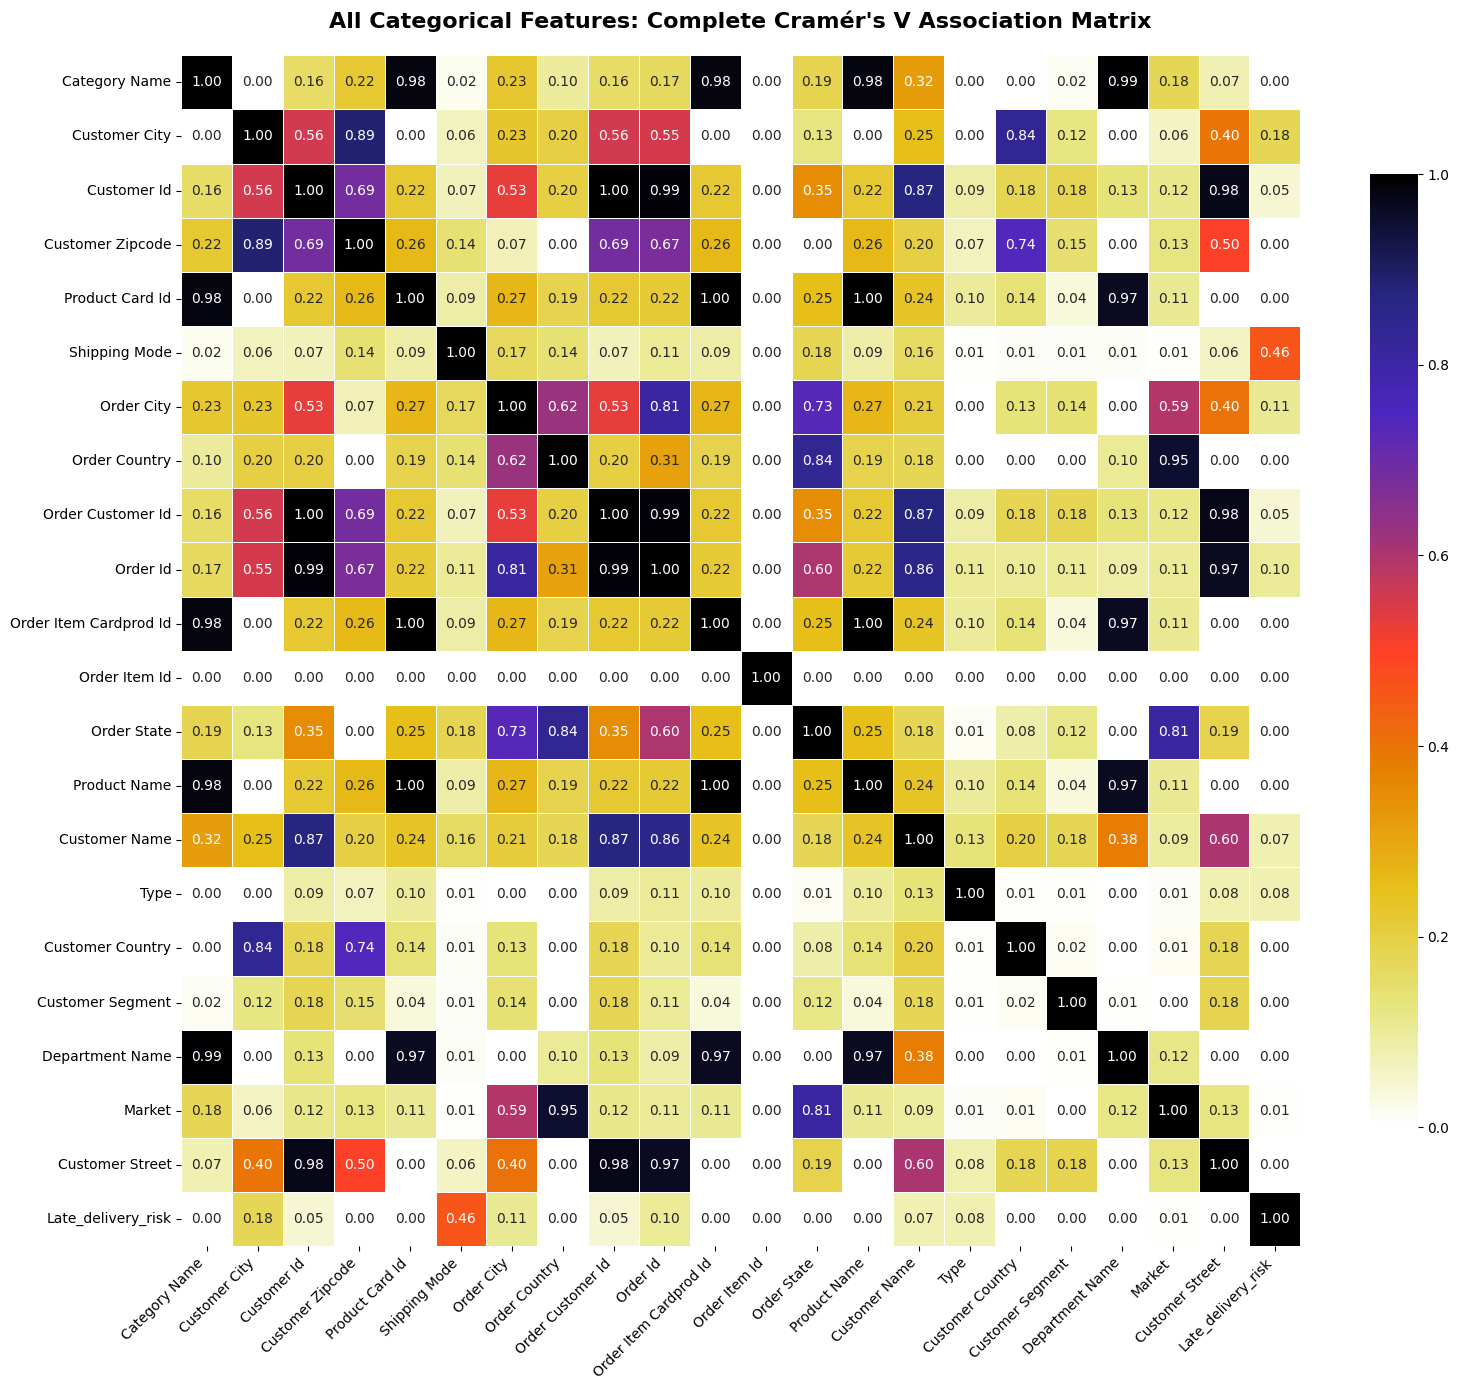

In [12]:
#Setting up the plot size
plt.figure(figsize=(16, 14))

#Generating the heatmap using the full Cramér's V matrix
sns.heatmap(
    v_matrix_full, 
    annot=True,             # Shows the V value in each cell
    cmap='CMRmap_r',         # Distinct palette for categorical relationships
    vmin=0, vmax=1,         # Cramér's V ranges from 0 to 1
    fmt=".2f",              # Rounds values to 2 decimal places
    linewidths=0.5,         # Adds clean gridlines between cells
    cbar_kws={"shrink": 0.8} # Slightly shrinks the colorbar to fit neatly
)

#Adding titles and adjust labels for readability
plt.title("All Categorical Features: Complete Cramér's V Association Matrix", fontsize=16, pad=20, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

#Preventing label clipping and display
plt.tight_layout()
plt.show()

In [13]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm


#Defining clean dataset for testing
remaining_numeric = [
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Latitude",
    "Longitude",
    "Order Item Discount",
    "Order Item Product Price",
    "Order Item Profit Ratio",
    "Order Item Quantity",
]

remaining_categorical = [
    "Category Name",
    "Customer City",
    "Customer Id",
    "Shipping Mode",
    "Order City",
    "Order Country",
    "Order State",
    "Type",
    "Customer Country",
    "Customer Segment",
    "Late_delivery_risk"

]

#Calculating Eta-Squared (Effect Size)
def calculate_anova_eta_squared(data, numeric_col, cat_col):
    # Building groups: one array of numeric values per category
    groups = [group[numeric_col].values 
              for _, group in data.groupby(cat_col)]
    
    #Dropping groups with fewr than 2 observations to avoid ANOVA errors
    groups = [g for g in groups if len(g) >= 2]

    # ANOVA F-test
    f_stat, p_value = stats.f_oneway(*groups)

     # Eta-squared
    all_values = np.concatenate(groups)
    grand_mean = all_values.mean()
    ss_total = np.sum((all_values - grand_mean)**2)
    ss_between = sum(len(g) * (np.mean(g) - grand_mean)**2 for g in groups)
    eta_sq = ss_between / ss_total if ss_total > 0 else 0.0

    return f_stat, p_value, eta_sq

results = []
for num_col in remaining_numeric:
    for cat_col in remaining_categorical:
        f_stat, p_value, eta_sq = calculate_anova_eta_squared(df_finalized_categorical, num_col, cat_col)
        results.append({
            'Numeric': num_col,
            'Categorical': cat_col,
            'F-stat': f_stat,
            'p-value': p_value,
            'Eta-squared': eta_sq
        })

results_df = pd.DataFrame(results)
print(results_df.sort_values('Eta-squared', ascending=False).to_string(index=False))


                      Numeric        Categorical       F-stat       p-value  Eta-squared
Days for shipment (scheduled)      Shipping Mode          inf  0.000000e+00 1.000000e+00
                     Latitude        Customer Id          inf  0.000000e+00 1.000000e+00
                    Longitude        Customer Id          inf  0.000000e+00 1.000000e+00
                     Latitude      Customer City 1.879890e+04  0.000000e+00 9.832520e-01
     Order Item Product Price      Category Name 1.674156e+05  0.000000e+00 9.784742e-01
                    Longitude      Customer City 3.310088e+03  0.000000e+00 9.117960e-01
                     Latitude   Customer Country 8.798086e+05  0.000000e+00 8.297532e-01
           Sales per customer      Category Name 1.007679e+04  0.000000e+00 7.323339e-01
          Order Item Quantity      Category Name 3.095333e+03  0.000000e+00 4.566483e-01
                    Longitude   Customer Country 1.508753e+05  0.000000e+00 4.552770e-01
          Order Item 

In [14]:
import pandas as pd
import numpy as np
from category_encoders import LeaveOneOutEncoder
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Loading Dataset again for preprocessing
df = pd.read_csv(r"C:\Project\Old_Project\Code\DataCoSupplyChainDataset.csv", encoding='latin-1')
target_col = 'Late_delivery_risk'
date_col = 'order date (DateOrders)' # Data will be chronologically split based on ordering date for training and testing
silo_col = 'Order Region'

# Clean whitespace from silo names so keys match cleanly
df[silo_col] = df[silo_col].astype(str).str.strip()

finalized_numeric_features = [
     "Benefit per order",
    "Sales per customer",
    "Order Item Discount",
    "Order Item Profit Ratio",
    "Order Item Quantity",
]

finalized_categorical_features = [
    "Category Name",
    "Customer City",
    "Shipping Mode",
    "Order City",
    "Order Country",
    "Order State",
    "Type",
    "Customer Country",
    "Customer Segment",
]

# Spliting data chronologically PER SILO into training, validation, and testing sets
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True) 

train_frames, val_frames, test_frames = [], [], []

for _, group in df.groupby(silo_col, group_keys=False):
    n = len(group)
    train_end = int(n * 0.70)
    val_end = int(n * 0.80)

    # Ensure validation and test sets get samples even for smaller silos
    if n >= 5:
        if train_end == val_end:
            val_end = train_end + 1
        if val_end == n:
            val_end = n - 1

    train_frames.append(group.iloc[:train_end])
    val_frames.append(group.iloc[train_end:val_end])
    test_frames.append(group.iloc[val_end:])

train_df = pd.concat(train_frames).sort_values(date_col).reset_index(drop=True)
val_df   = pd.concat(val_frames).sort_values(date_col).reset_index(drop=True)
test_df  = pd.concat(test_frames).sort_values(date_col).reset_index(drop=True)

print(f"Train: {len(train_df)} rows | Val: {len(val_df)} rows | Test: {len(test_df)} rows")

# Labeling categorical features based on their cardinality
CARDINALITY_THRESHOLD = 50

high_card_cols = []
low_card_cols = []

for col in finalized_categorical_features:
    n_unique = train_df[col].nunique()
    if n_unique > CARDINALITY_THRESHOLD:
        high_card_cols.append(col)
    else:
        low_card_cols.append(col)

print("High-cardinality (Leave-One-Out):", high_card_cols)
print("Low-cardinality (One-Hot):", low_card_cols)

# LOO encoding high cardianlity categorical features
loo_encoder = LeaveOneOutEncoder(cols=high_card_cols, sigma=0.05)

train_loo = loo_encoder.fit_transform(train_df[high_card_cols], train_df[target_col]) # .fit_transform() use full loo formula

val_loo   = loo_encoder.transform(val_df[high_card_cols]) # Validation (.transform automatically remain refrained from adding noise. just replace with values from training set)
test_loo  = loo_encoder.transform(test_df[high_card_cols]) # Testing

# One-Hot encoding low cardinality categorical features (Kind of same procedure for fitting in validation and testing sets)
onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
onehot_encoder.fit(train_df[low_card_cols])

train_onehot = onehot_encoder.transform(train_df[low_card_cols])
val_onehot   = onehot_encoder.transform(val_df[low_card_cols])
test_onehot  = onehot_encoder.transform(test_df[low_card_cols])

onehot_names = onehot_encoder.get_feature_names_out(low_card_cols) # It creates one less dummy columns as the number of unique values in the features
train_onehot = pd.DataFrame(train_onehot, columns=onehot_names, index=train_df.index)
val_onehot   = pd.DataFrame(val_onehot, columns=onehot_names, index=val_df.index)
test_onehot  = pd.DataFrame(test_onehot, columns=onehot_names, index=test_df.index)

# Scaling numerical features and LOO features using StandardScaler so that features with larger magnitude do not dominate the training
# Building dataframe
train_num_loo = pd.concat([train_df[finalized_numeric_features], train_loo], axis=1)
val_num_loo   = pd.concat([val_df[finalized_numeric_features], val_loo], axis=1)
test_num_loo  = pd.concat([test_df[finalized_numeric_features], test_loo], axis=1)

scaler = StandardScaler()
scaler.fit(train_num_loo) # For preventing leakage scaling info will only be extracted from training set

train_scaled_arr = scaler.transform(train_num_loo)
val_scaled_arr   = scaler.transform(val_num_loo)
test_scaled_arr  = scaler.transform(test_num_loo)

train_scaled = pd.DataFrame(train_scaled_arr, columns=train_num_loo.columns, index=train_num_loo.index)
val_scaled   = pd.DataFrame(val_scaled_arr, columns=val_num_loo.columns, index=val_num_loo.index)
test_scaled  = pd.DataFrame(test_scaled_arr, columns=test_num_loo.columns, index=test_num_loo.index)

# Preparing final data pipelines for model training and evaluation
X_train = pd.concat([train_scaled, train_onehot], axis=1).reset_index(drop=True) # Preparing one dataset for all features
X_val   = pd.concat([val_scaled, val_onehot], axis=1).reset_index(drop=True)
X_test  = pd.concat([test_scaled, test_onehot], axis=1).reset_index(drop=True)

y_train = train_df[target_col].reset_index(drop=True)
y_val   = val_df[target_col].reset_index(drop=True)
y_test  = test_df[target_col].reset_index(drop=True)

print("Final shapes:")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

Train: 126353 rows | Val: 18053 rows | Test: 36113 rows
High-cardinality (Leave-One-Out): ['Customer City', 'Order City', 'Order Country', 'Order State']
Low-cardinality (One-Hot): ['Category Name', 'Shipping Mode', 'Type', 'Customer Country', 'Customer Segment']
Final shapes:
X_train: (126353, 53)
X_val:   (18053, 53)
X_test:  (36113, 53)


In [15]:
#Partitioning the data into silos based on the 'Order Region' feature as no supplier is mentioned in the dataset
silo_col = 'Order Region'

#Dividing all three portions of the dataset into silos
silo_train = train_df[silo_col].reset_index(drop=True)
silo_val   = val_df[silo_col].reset_index(drop=True)
silo_test  = test_df[silo_col].reset_index(drop=True)

#Finding the silos
silos = sorted(df[silo_col].dropna().unique())
print(f"\nFound {len(silos)} silos: {silos}")

#Dataframes for training, validation as test as per silos
train_by_silo = {}
val_by_silo   = {}
test_by_silo  = {}


#Making subsets as per silos for the data 
for silo in silos:
    train_mask = (silo_train == silo).values
    val_mask   = (silo_val == silo).values
    test_mask  = (silo_test == silo).values
 
    train_by_silo[silo] = (
        X_train[train_mask].reset_index(drop=True),
        y_train[train_mask].reset_index(drop=True)
    )
    val_by_silo[silo] = (
        X_val[val_mask].reset_index(drop=True),
        y_val[val_mask].reset_index(drop=True)
    )
    test_by_silo[silo] = (
        X_test[test_mask].reset_index(drop=True),
        y_test[test_mask].reset_index(drop=True)
    )
 
    print(f"  {silo}: train={train_mask.sum()}, val={val_mask.sum()}, test={test_mask.sum()}")


Found 23 silos: ['Canada', 'Caribbean', 'Central Africa', 'Central America', 'Central Asia', 'East Africa', 'East of USA', 'Eastern Asia', 'Eastern Europe', 'North Africa', 'Northern Europe', 'Oceania', 'South America', 'South Asia', 'South of  USA', 'Southeast Asia', 'Southern Africa', 'Southern Europe', 'US Center', 'West Africa', 'West Asia', 'West of USA', 'Western Europe']
  Canada: train=671, val=96, test=192
  Caribbean: train=5822, val=832, test=1664
  Central Africa: train=1173, val=168, test=336
  Central America: train=19838, val=2834, test=5669
  Central Asia: train=387, val=55, test=111
  East Africa: train=1296, val=185, test=371
  East of USA: train=4840, val=692, test=1383
  Eastern Asia: train=5096, val=728, test=1456
  Eastern Europe: train=2744, val=392, test=784
  North Africa: train=2262, val=323, test=647
  Northern Europe: train=6854, val=979, test=1959
  Oceania: train=7103, val=1015, test=2030
  South America: train=10454, val=1494, test=2987
  South Asia: tra

In [25]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score
import copy
import numpy as np


#Defining hyperparameters for the model
INPUT_DIM = X_train.shape[1]
BATCH_SIZE = 32
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4        # Added weight decay parameter (L2 Regularization)
DROPOUT_RATE = 0.2         # Added dropout probability
MAX_EPOCHS = 1000          # hard ceiling; early stopping will trigger first
PATIENCE = 10               # stop after 10 consecutive epochs with no val-loss improvement
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


#ANN Architecture
class LocalANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            #nn.Dropout(DROPOUT_RATE),   # Added Dropout after Layer 1 (Check if results improve)

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.BatchNorm1d(32),
            #nn.Dropout(DROPOUT_RATE),   # Added Dropout after Layer 2

            #nn.Linear(100, 100),
            #nn.ReLU(),
            #nn.BatchNorm1d(100),

            nn.Linear(32, 2)   # raw logits. CrossEntropyLoss handles softmax
        )

    def forward(self, x):
        return self.net(x)


def make_loader(X, y, batch_size, shuffle):
    X_t = torch.tensor(X.values, dtype=torch.float32)
    y_t = torch.tensor(y.values, dtype=torch.long)   # CrossEntropyLoss needs class indices (long)
    dataset = TensorDataset(X_t, y_t)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_true = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            total_loss += loss.item() * X_batch.size(0)

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_true.extend(y_batch.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, np.array(all_true), np.array(all_preds)


def train_one_silo(X_tr, y_tr, X_val, y_val, input_dim):
    model = LocalANN(input_dim).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    # Added weight_decay to the Adam optimizer
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE) #Can Check if Adam fares better

    train_loader = make_loader(X_tr, y_tr, BATCH_SIZE, shuffle=True)
    val_loader = make_loader(X_val, y_val, BATCH_SIZE, shuffle=False)

    best_val_loss = float("inf")
    best_state = None
    epochs_no_improve = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

        val_loss, _, _ = evaluate(model, val_loader, criterion)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= PATIENCE:
                print(f"    Early stopping at epoch {epoch} (best val_loss={best_val_loss:.4f})")
                break

    model.load_state_dict(best_state)
    return model, criterion


# Training silos
results = []

for silo in sorted(train_by_silo.keys()):
    print(f"\n=== Training Local Model: {silo} ===")

    X_tr, y_tr = train_by_silo[silo]
    X_val, y_val = val_by_silo[silo]
    X_te, y_te = test_by_silo[silo]

    model, criterion = train_one_silo(X_tr, y_tr, X_val, y_val, INPUT_DIM)

    test_loader = make_loader(X_te, y_te, BATCH_SIZE, shuffle=False)
    test_loss, y_true, y_pred = evaluate(model, test_loader, criterion)

    f1_ontime = f1_score(y_true, y_pred, pos_label=0)
    f1_delayed = f1_score(y_true, y_pred, pos_label=1)
    fw_score = f1_score(y_true, y_pred, average='weighted')

    print(f"    Test loss={test_loss:.4f}  F1(on-time)={f1_ontime:.4f}  "
          f"F1(delayed)={f1_delayed:.4f}  Fw={fw_score:.4f}")

    results.append({
        'Silo': silo,
        'Test Loss': test_loss,
        'F1 On-time': f1_ontime,
        'F1 Delayed': f1_delayed,
        'Fw': fw_score
    })

import pandas as pd
results_df = pd.DataFrame(results)
print("\n=== LOCAL MODEL SUMMARY ===")
print(results_df.to_string(index=False))
print(f"\nAverage Fw across all silos: {results_df['Fw'].mean():.4f}")

local_df = results_df.copy()


=== Training Local Model: Canada ===
    Early stopping at epoch 64 (best val_loss=0.5585)
    Test loss=0.5937  F1(on-time)=0.7009  F1(delayed)=0.6235  Fw=0.6655

=== Training Local Model: Caribbean ===
    Early stopping at epoch 53 (best val_loss=0.5252)
    Test loss=0.5948  F1(on-time)=0.7164  F1(delayed)=0.6565  Fw=0.6855

=== Training Local Model: Central Africa ===
    Early stopping at epoch 11 (best val_loss=0.7126)
    Test loss=0.7169  F1(on-time)=0.3917  F1(delayed)=0.6620  Fw=0.5518

=== Training Local Model: Central America ===
    Early stopping at epoch 22 (best val_loss=0.5960)
    Test loss=0.5767  F1(on-time)=0.6842  F1(delayed)=0.6699  Fw=0.6764

=== Training Local Model: Central Asia ===
    Early stopping at epoch 11 (best val_loss=0.7261)
    Test loss=0.7478  F1(on-time)=0.2243  F1(delayed)=0.2783  Fw=0.2637

=== Training Local Model: East Africa ===
    Early stopping at epoch 63 (best val_loss=0.5962)
    Test loss=0.5900  F1(on-time)=0.6746  F1(delayed)=0.7

In [26]:
import copy
import numpy as np
import pandas as pd
import sklearn.metrics
from sklearn.metrics import f1_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Defining hyperparameters for the federated setup
INPUT_DIM = X_train.shape[1]
BATCH_SIZE = 32
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.2
ROUNDS = 1000  # Total federated communication rounds
LOCAL_EPOCHS = 5  # Local epochs per round
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ANN Architecture
class LocalANN(nn.Module):

  def __init__(self, input_dim):
    super().__init__()
    self.net = nn.Sequential(
        nn.Linear(input_dim, 64),
        nn.ReLU(),
        nn.BatchNorm1d(64),
        # nn.Dropout(DROPOUT_RATE),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.BatchNorm1d(32),
        # nn.Dropout(DROPOUT_RATE),
        nn.Linear(32, 2),  # raw logits. CrossEntropyLoss handles softmax
    )

  def forward(self, x):
    return self.net(x)


def make_loader(X, y, batch_size, shuffle):
  X_t = torch.tensor(X.values, dtype=torch.float32)
  y_t = torch.tensor(y.values, dtype=torch.long)
  dataset = TensorDataset(X_t, y_t)
  return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


def evaluate(model, loader, criterion):
  model.eval()
  total_loss = 0.0
  all_preds, all_true = [], []
  with torch.no_grad():
    for X_batch, y_batch in loader:
      X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
      logits = model(X_batch)
      loss = criterion(logits, y_batch)
      total_loss += loss.item() * X_batch.size(0)

      preds = torch.argmax(logits, dim=1)
      all_preds.extend(preds.cpu().numpy())
      all_true.extend(y_batch.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  return avg_loss, np.array(all_true), np.array(all_preds)


# Utility to perform federated averaging across state dicts
def average_weights(w_list, sample_counts):
  total_samples = sum(sample_counts)
  w_avg = copy.deepcopy(w_list[0])
  for key in w_avg.keys():
    w_avg[key] = w_avg[key] * (sample_counts[0] / total_samples)
    for i in range(1, len(w_list)):
      w_avg[key] += w_list[i][key] * (sample_counts[i] / total_samples)
  return w_avg


# Federated Learning Setup
silos = sorted(train_by_silo.keys())
train_loaders = {
    silo: make_loader(
        train_by_silo[silo][0],
        train_by_silo[silo][1],
        BATCH_SIZE,
        shuffle=True,
    )
    for silo in silos
}
val_loaders = {
    silo: make_loader(
        val_by_silo[silo][0],
        val_by_silo[silo][1],
        BATCH_SIZE,
        shuffle=False,
    )
    for silo in silos
}
test_loaders = {
    silo: make_loader(
        test_by_silo[silo][0],
        test_by_silo[silo][1],
        BATCH_SIZE,
        shuffle=False,
    )
    for silo in silos
}

# Pre-calculate sample counts per silo for FedAvg weighting
silo_sample_counts = [len(train_by_silo[silo][0]) for silo in silos]

global_model = LocalANN(INPUT_DIM).to(DEVICE)
criterion = nn.CrossEntropyLoss()

print("=== STARTING FEDERATED TRAINING (FedAvg) ===")

for r in range(1, ROUNDS + 1):
  local_weights = []

  # Training on each silo locally
  for silo in silos:
    local_model = LocalANN(INPUT_DIM).to(DEVICE)
    local_model.load_state_dict(global_model.state_dict())
    optimizer = torch.optim.SGD(local_model.parameters(), lr=LEARNING_RATE)

    local_model.train()
    loader = train_loaders[silo]

    for epoch in range(LOCAL_EPOCHS):
      # Process only ONE single batch per local epoch as requested
      for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer.zero_grad()
        logits = local_model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        break  # Breaking after 1 batch calculation

    local_weights.append(copy.deepcopy(local_model.state_dict()))

  # Aggregate local model parameters on server
  global_weights = average_weights(local_weights, silo_sample_counts)
  global_model.load_state_dict(global_weights)

  # Monitor progress every 10 communication rounds
  if r % 10 == 0 or r == ROUNDS:
    train_losses = []
    val_fw_scores = []

    for silo in silos:
      # Evaluating Training Loss (1 batch sample)
      X_tr_b, y_tr_b = next(iter(train_loaders[silo]))
      X_tr_b, y_tr_b = X_tr_b.to(DEVICE), y_tr_b.to(DEVICE)
      global_model.eval()
      with torch.no_grad():
        t_loss = criterion(global_model(X_tr_b), y_tr_b).item()
      train_losses.append(t_loss)

      # Evaluate Validation Fw Score
      _, y_v_true, y_v_pred = evaluate(
          global_model, val_loaders[silo], criterion
      )
      val_fw = f1_score(y_v_true, y_v_pred, average='weighted')
      val_fw_scores.append(val_fw)

    avg_train_loss = np.mean(train_losses)
    avg_val_fw = np.mean(val_fw_scores)
    print(
        f"Round {r:4d}/{ROUNDS} | Mean Train Loss:"
        f" {avg_train_loss:.4f} | Mean Val Fw: {avg_val_fw:.4f}"
    )


# Final Evaluation and Personalization
print("\n=== FINAL TEST EVALUATION WITH LOCAL PERSONALIZATION ===")
results = []

# Takes parameters from the last communication round (Round 1000)
final_global_weights = copy.deepcopy(global_model.state_dict())

for silo in silos:
  # Initialize local model with last round's global weights
  pers_model = LocalANN(INPUT_DIM).to(DEVICE)
  pers_model.load_state_dict(final_global_weights)
  optimizer = torch.optim.SGD(pers_model.parameters(), lr=0.005)

  # Personalization: 1 gradient descent step using only 1 data batch
  pers_model.train()
  X_batch, y_batch = next(iter(train_loaders[silo]))
  X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)

  optimizer.zero_grad()
  logits = pers_model(X_batch)
  loss = criterion(logits, y_batch)
  loss.backward()
  optimizer.step()

  # Test evaluation on personalized model
  test_loss, y_true, y_pred = evaluate(
      pers_model, test_loaders[silo], criterion
  )

  f1_ontime = f1_score(y_true, y_pred, pos_label=0)
  f1_delayed = f1_score(y_true, y_pred, pos_label=1)
  fw_score = f1_score(y_true, y_pred, average='weighted')

  print(
      f"Silo: {silo:18s} | Test loss={test_loss:.4f} "
      f"F1(on-time)={f1_ontime:.4f}  F1(delayed)={f1_delayed:.4f} "
      f"Fw={fw_score:.4f}"
  )

  results.append({
      'Silo': silo,
      'Test Loss': test_loss,
      'F1 On-time': f1_ontime,
      'F1 Delayed': f1_delayed,
      'Fw': fw_score,
  })

results_df = pd.DataFrame(results)
print("\n=== FEDERATED MODEL SUMMARY ===")
print(results_df.to_string(index=False))
print(f"\nAverage Fw across all silos: {results_df['Fw'].mean():.4f}")

fedavg_df = results_df.copy()

=== STARTING FEDERATED TRAINING (FedAvg) ===
Round   10/1000 | Mean Train Loss: 0.7686 | Mean Val Fw: 0.4527
Round   20/1000 | Mean Train Loss: 0.7402 | Mean Val Fw: 0.4686
Round   30/1000 | Mean Train Loss: 0.7233 | Mean Val Fw: 0.4782
Round   40/1000 | Mean Train Loss: 0.7089 | Mean Val Fw: 0.4909
Round   50/1000 | Mean Train Loss: 0.7147 | Mean Val Fw: 0.5033
Round   60/1000 | Mean Train Loss: 0.7005 | Mean Val Fw: 0.5198
Round   70/1000 | Mean Train Loss: 0.6717 | Mean Val Fw: 0.5284
Round   80/1000 | Mean Train Loss: 0.6707 | Mean Val Fw: 0.5378
Round   90/1000 | Mean Train Loss: 0.6586 | Mean Val Fw: 0.5491
Round  100/1000 | Mean Train Loss: 0.6512 | Mean Val Fw: 0.5560
Round  110/1000 | Mean Train Loss: 0.6303 | Mean Val Fw: 0.5623
Round  120/1000 | Mean Train Loss: 0.6414 | Mean Val Fw: 0.5728
Round  130/1000 | Mean Train Loss: 0.6187 | Mean Val Fw: 0.5795
Round  140/1000 | Mean Train Loss: 0.6231 | Mean Val Fw: 0.5826
Round  150/1000 | Mean Train Loss: 0.6299 | Mean Val Fw: 0.

In [27]:
#Implementin Personalized Federated Averaging (First Order meaning no Hessian Matrix)
import copy
import itertools
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset


#Hyperparameters for Personalized Federated Averaging (pFedAvg)
INPUT_DIM = X_train.shape[1]
BATCH_SIZE = 32
ALPHA = 0.005        
BETA = 0.001        # meta-gradient step size
PERSONALIZATION_LR = ALPHA   # personalization uses the same step size as the lookahead step
PERSONALIZATION_STEPS = 1
ROUNDS = 1000
LOCAL_EPOCHS = 10    # local steps per round, per silo (same structure as FedAvg script)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ANN Architecture (identical to FedAvg script)
class LocalANN(nn.Module):
 
  def __init__(self, input_dim):
    super().__init__()
    self.net = nn.Sequential(
        nn.Linear(input_dim, 64),
        nn.ReLU(),
        nn.BatchNorm1d(64),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.BatchNorm1d(32),
        nn.Linear(32, 2),  # raw logits -- CrossEntropyLoss handles softmax
    )
 
  def forward(self, x):
    return self.net(x)
 
 
def make_loader(X, y, batch_size, shuffle):
  X_t = torch.tensor(X.values, dtype=torch.float32)
  y_t = torch.tensor(y.values, dtype=torch.long)
  dataset = TensorDataset(X_t, y_t)
  return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)



def evaluate(model, loader, criterion):
  model.eval()
  total_loss = 0.0
  all_preds, all_true = [], []
  with torch.no_grad():
    for X_batch, y_batch in loader:
      X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
      logits = model(X_batch)
      loss = criterion(logits, y_batch)
      total_loss += loss.item() * X_batch.size(0) #Summing losses across batches in a silo
 
      preds = torch.argmax(logits, dim=1)
      all_preds.extend(preds.cpu().numpy())
      all_true.extend(y_batch.cpu().numpy())
 
  avg_loss = total_loss / len(loader.dataset)
  return avg_loss, np.array(all_true), np.array(all_preds)

def average_weights(w_list, sample_counts):
  total_samples = sum(sample_counts)
  w_avg = copy.deepcopy(w_list[0])
  for key in w_avg.keys():
    w_avg[key] = w_avg[key] * (sample_counts[0] / total_samples)
    for i in range(1, len(w_list)):
      w_avg[key] += w_list[i][key] * (sample_counts[i] / total_samples)
  return w_avg


def per_fedavg_local_step(model, batch1, batch2, criterion):

  X1, y1 = batch1
  X2, y2 = batch2
  X1, y1 = X1.to(DEVICE), y1.to(DEVICE)
  X2, y2 = X2.to(DEVICE), y2.to(DEVICE)


  model.train()
 
  # Save original parameters from last epoch/local step
  original_params = [p.clone().detach() for p in model.parameters()]
 
  #Calculating look ahead gradient using support batch data
  model.zero_grad()
  logits1 = model(X1)
  loss1 = criterion(logits1, y1)
  loss1.backward()
 
  with torch.no_grad():
    for p in model.parameters():
      p.copy_((p - ALPHA * p.grad).detach())   # w' = w - alpha * grad(w)
 
  #Calculating meta-gradient using query batch
  model.zero_grad()
  logits2 = model(X2)
  loss2 = criterion(logits2, y2)
  loss2.backward()
  meta_grads = [p.grad.clone().detach() for p in model.parameters()]
 
  #Applying meta-gradients on parameters from last epoch
  with torch.no_grad():
    for p, orig, g in zip(model.parameters(), original_params, meta_grads):
      p.copy_((orig - BETA * g).detach())
 
  return loss1.item(), loss2.item()

#Data Setup for PO-Per Fed Avg
silos = sorted(train_by_silo.keys())
train_loaders = {
    silo: make_loader(train_by_silo[silo][0], train_by_silo[silo][1], BATCH_SIZE, shuffle=True)
    for silo in silos
}
val_loaders = {
    silo: make_loader(val_by_silo[silo][0], val_by_silo[silo][1], BATCH_SIZE, shuffle=False)
    for silo in silos
}
test_loaders = {
    silo: make_loader(test_by_silo[silo][0], test_by_silo[silo][1], BATCH_SIZE, shuffle=False)
    for silo in silos
}

# Infinite cycling is need as data distribution across silos is uneven and some silos may have fewer batches than others. This ensures that each silo can provide batches for the entire duration of the federated training rounds.
train_iters = {silo: itertools.cycle(train_loaders[silo]) for silo in silos}
 
silo_sample_counts = [len(train_by_silo[silo][0]) for silo in silos]
 
global_model = LocalANN(INPUT_DIM).to(DEVICE)
criterion = nn.CrossEntropyLoss()


print("=== STARTING FEDERATED TRAINING (Per-FedAvg, first-order) ===")
for r in range(1, ROUNDS + 1):
  local_weights = []
 
  for silo in silos:
    local_model = LocalANN(INPUT_DIM).to(DEVICE)
    local_model.load_state_dict(global_model.state_dict())
 
    for epoch in range(LOCAL_EPOCHS):
      batch1 = next(train_iters[silo])
      batch2 = next(train_iters[silo])   # must be a DIFFERENT batch from batch1
      per_fedavg_local_step(local_model, batch1, batch2, criterion)
 
    local_weights.append(copy.deepcopy(local_model.state_dict()))
 
  global_weights = average_weights(local_weights, silo_sample_counts)
  global_model.load_state_dict(global_weights)
 
  if r % 10 == 0 or r == ROUNDS:
    val_fw_scores = []
    for silo in silos:
      _, y_v_true, y_v_pred = evaluate(global_model, val_loaders[silo], criterion)
      val_fw_scores.append(f1_score(y_v_true, y_v_pred, average='weighted'))
    print(f"Round {r:4d}/{ROUNDS} | Mean Val Fw: {np.mean(val_fw_scores):.4f}")

#Final Evaluation and Personalization
print("\n=== FINAL TEST EVALUATION WITH PERSONALIZATION ===")
results = []
final_global_weights = copy.deepcopy(global_model.state_dict())
 
for silo in silos:
  pers_model = LocalANN(INPUT_DIM).to(DEVICE)
  pers_model.load_state_dict(final_global_weights)
  optimizer = torch.optim.SGD(pers_model.parameters(), lr=PERSONALIZATION_LR)
 
  pers_model.train()
  pers_iter = itertools.cycle(train_loaders[silo])
  for _ in range(PERSONALIZATION_STEPS):
    X_batch, y_batch = next(pers_iter)
    X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
    optimizer.zero_grad()
    loss = criterion(pers_model(X_batch), y_batch)
    loss.backward()
    optimizer.step()
 
  test_loss, y_true, y_pred = evaluate(pers_model, test_loaders[silo], criterion)
 
  f1_ontime = f1_score(y_true, y_pred, pos_label=0)
  f1_delayed = f1_score(y_true, y_pred, pos_label=1)
  fw_score = f1_score(y_true, y_pred, average='weighted')
 
  print(f"Silo: {silo:18s} | Test loss={test_loss:.4f} "
        f"F1(on-time)={f1_ontime:.4f}  F1(delayed)={f1_delayed:.4f}  Fw={fw_score:.4f}")
 
  results.append({'Silo': silo, 'Test Loss': test_loss, 'F1 On-time': f1_ontime,
                   'F1 Delayed': f1_delayed, 'Fw': fw_score})
 
results_df = pd.DataFrame(results)
print("\n=== PER-FEDAVG SUMMARY ===")
print(results_df.to_string(index=False))
print(f"\nAverage Fw across all silos: {results_df['Fw'].mean():.4f}")

perfedavg_df = results_df.copy()

=== STARTING FEDERATED TRAINING (Per-FedAvg, first-order) ===
Round   10/1000 | Mean Val Fw: 0.5284
Round   20/1000 | Mean Val Fw: 0.5494
Round   30/1000 | Mean Val Fw: 0.5686
Round   40/1000 | Mean Val Fw: 0.5816
Round   50/1000 | Mean Val Fw: 0.5984
Round   60/1000 | Mean Val Fw: 0.6057
Round   70/1000 | Mean Val Fw: 0.6126
Round   80/1000 | Mean Val Fw: 0.6203
Round   90/1000 | Mean Val Fw: 0.6236
Round  100/1000 | Mean Val Fw: 0.6268
Round  110/1000 | Mean Val Fw: 0.6309
Round  120/1000 | Mean Val Fw: 0.6319
Round  130/1000 | Mean Val Fw: 0.6328
Round  140/1000 | Mean Val Fw: 0.6349
Round  150/1000 | Mean Val Fw: 0.6387
Round  160/1000 | Mean Val Fw: 0.6396
Round  170/1000 | Mean Val Fw: 0.6411
Round  180/1000 | Mean Val Fw: 0.6455
Round  190/1000 | Mean Val Fw: 0.6455
Round  200/1000 | Mean Val Fw: 0.6463
Round  210/1000 | Mean Val Fw: 0.6483
Round  220/1000 | Mean Val Fw: 0.6489
Round  230/1000 | Mean Val Fw: 0.6487
Round  240/1000 | Mean Val Fw: 0.6506
Round  250/1000 | Mean Val

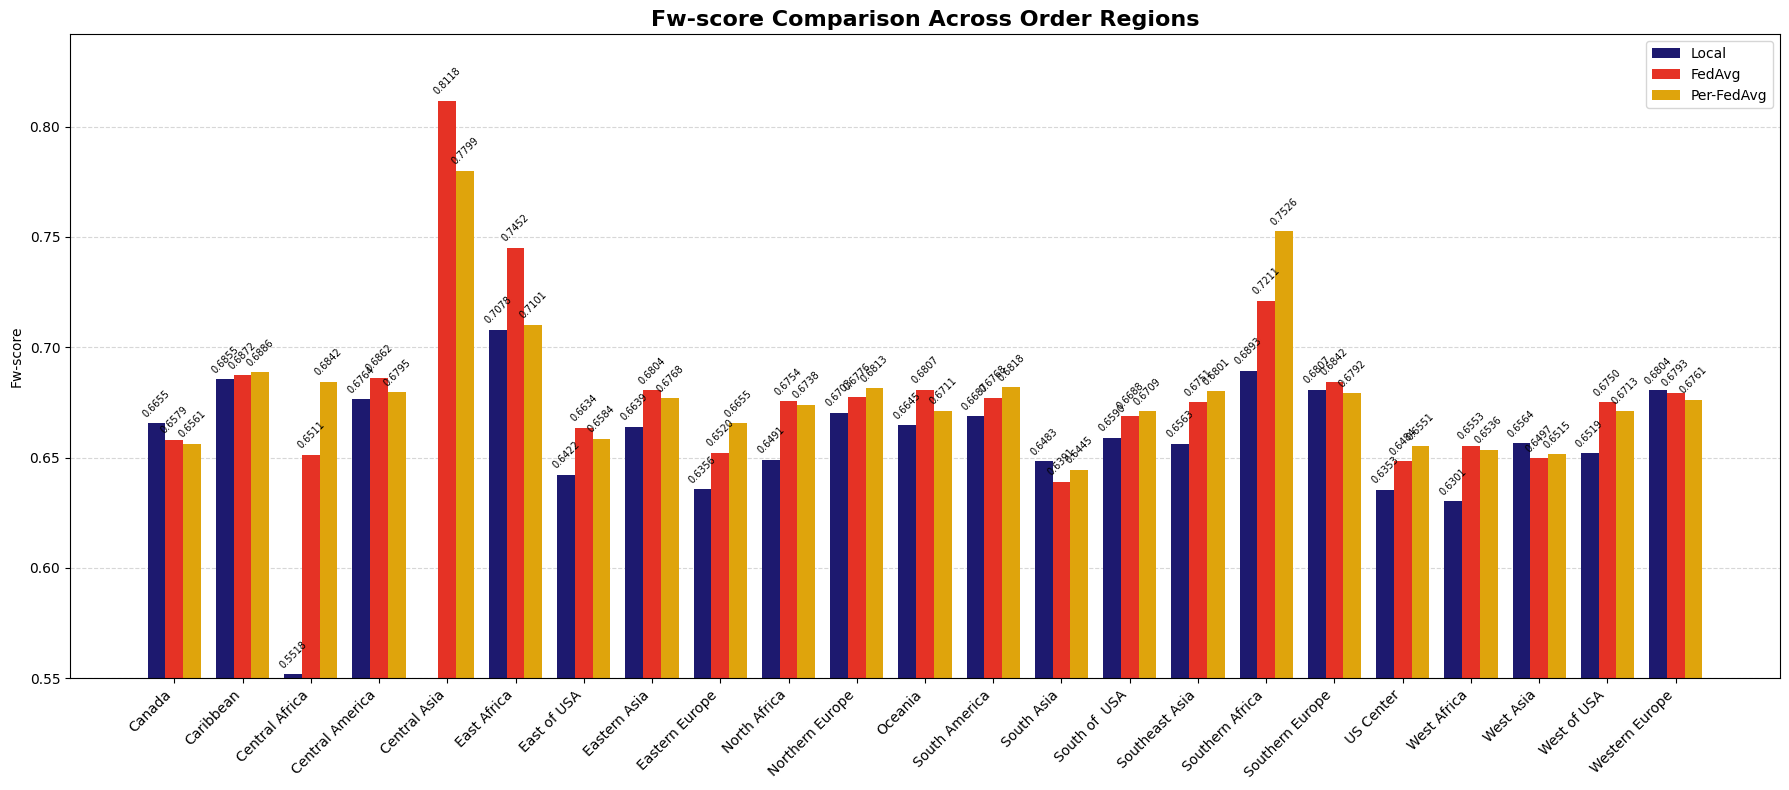

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Expects local_df, fedavg_df, perfedavg_df already prepared (see note above),
# each with columns 'Silo' and 'Fw'.

# Merge the three results into one table, aligned by Silo
merged = local_df[['Silo', 'Fw']].rename(columns={'Fw': 'Local'})
merged = merged.merge(fedavg_df[['Silo', 'Fw']].rename(columns={'Fw': 'FedAvg'}), on='Silo')
merged = merged.merge(perfedavg_df[['Silo', 'Fw']].rename(columns={'Fw': 'Per-FedAvg'}), on='Silo')
merged = merged.sort_values('Silo').reset_index(drop=True)

# Bar positions
x = np.arange(len(merged))
width = 0.26

fig, ax = plt.subplots(figsize=(18, 8))

bars_local = ax.bar(x - width, merged['Local'], width, label='Local', color='#1d196f')
bars_fedavg = ax.bar(x, merged['FedAvg'], width, label='FedAvg', color='#e53225')
bars_perfed = ax.bar(x + width, merged['Per-FedAvg'], width, label='Per-FedAvg', color='#dfa40c')

# Add value labels on top of each bar
for bars in [bars_local, bars_fedavg, bars_perfed]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=7, rotation=45)

ax.set_title('Fw-score Comparison Across Order Regions', fontsize=16, weight='bold')
ax.set_ylabel('Fw-score')
ax.set_xticks(x)
ax.set_xticklabels(merged['Silo'], rotation=45, ha='right')
ax.set_ylim(0.55, merged[['Local', 'FedAvg', 'Per-FedAvg']].values.max() + 0.03)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('fw_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

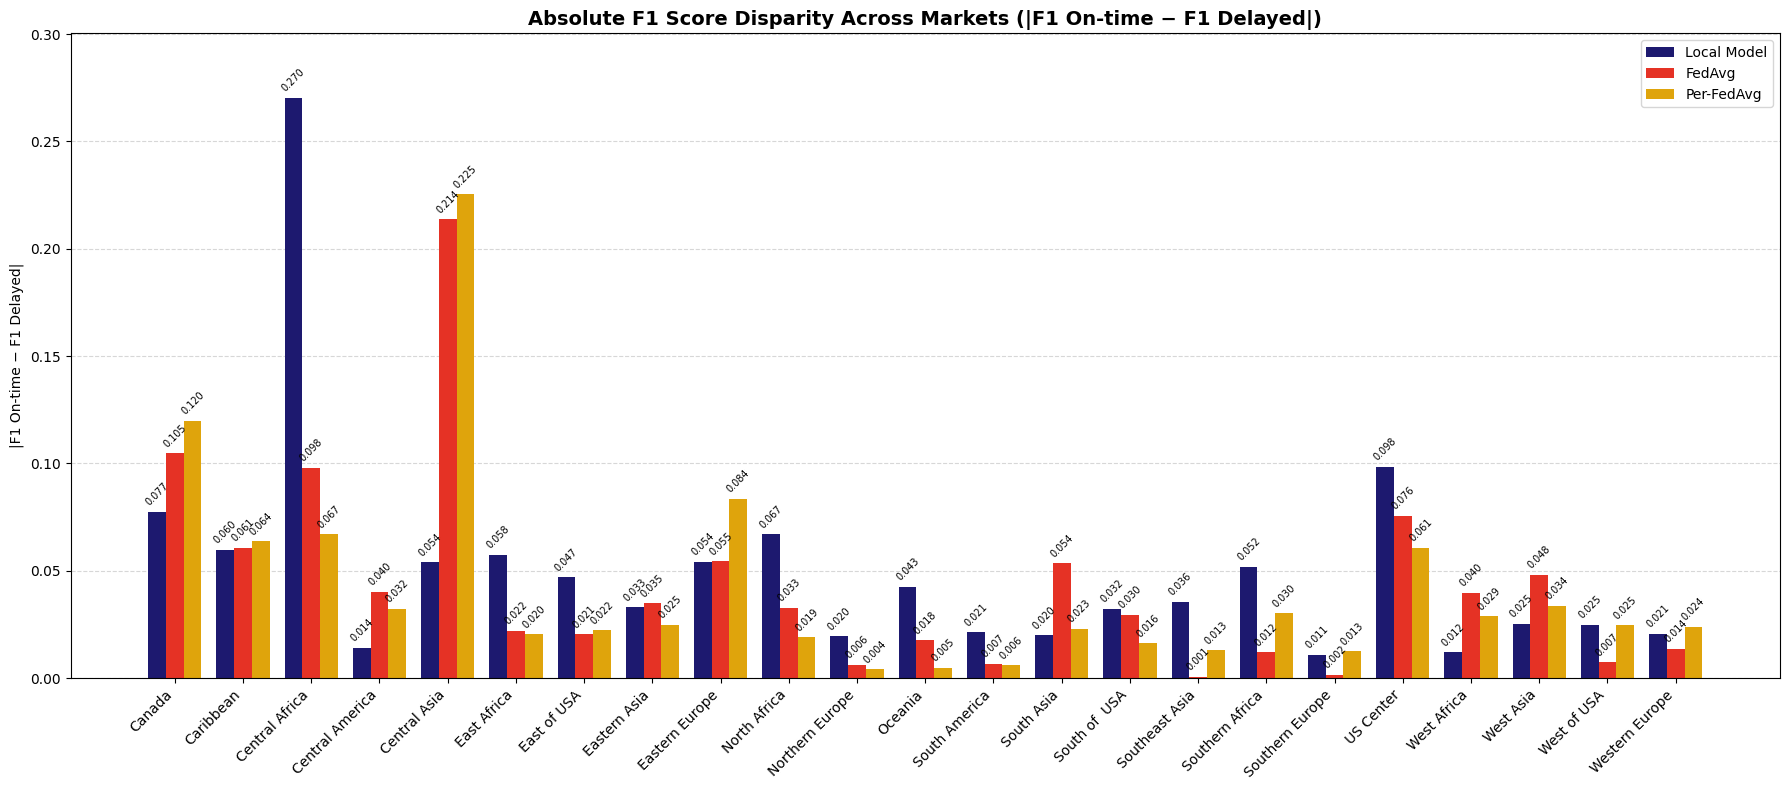

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Expects local_df, fedavg_df, perfedavg_df already prepared (see earlier script),
# each with columns 'Silo', 'F1 On-time', 'F1 Delayed'.

def add_disparity(df, label):
    out = df[['Silo', 'F1 On-time', 'F1 Delayed']].copy()
    out[label] = (out['F1 On-time'] - out['F1 Delayed']).abs()
    return out[['Silo', label]]

local_gap = add_disparity(local_df, 'Local Model')
fedavg_gap = add_disparity(fedavg_df, 'FedAvg')
perfed_gap = add_disparity(perfedavg_df, 'Per-FedAvg')

merged = local_gap.merge(fedavg_gap, on='Silo').merge(perfed_gap, on='Silo')
merged = merged.sort_values('Silo').reset_index(drop=True)

x = np.arange(len(merged))
width = 0.26

fig, ax = plt.subplots(figsize=(18, 8))

bars_local = ax.bar(x - width, merged['Local Model'], width, label='Local Model', color='#1d196f')
bars_fedavg = ax.bar(x, merged['FedAvg'], width, label='FedAvg', color='#e53225')
bars_perfed = ax.bar(x + width, merged['Per-FedAvg'], width, label='Per-FedAvg', color='#dfa40c')

for bars in [bars_local, bars_fedavg, bars_perfed]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=7, rotation=45)

ax.set_title('Absolute F1 Score Disparity Across Markets (|F1 On-time − F1 Delayed|)',
              fontsize=14, weight='bold')
ax.set_ylabel('|F1 On-time − F1 Delayed|')
ax.set_xticks(x)
ax.set_xticklabels(merged['Silo'], rotation=45, ha='right')
ax.set_ylim(0, merged[['Local Model', 'FedAvg', 'Per-FedAvg']].values.max() + 0.03)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('disparity_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

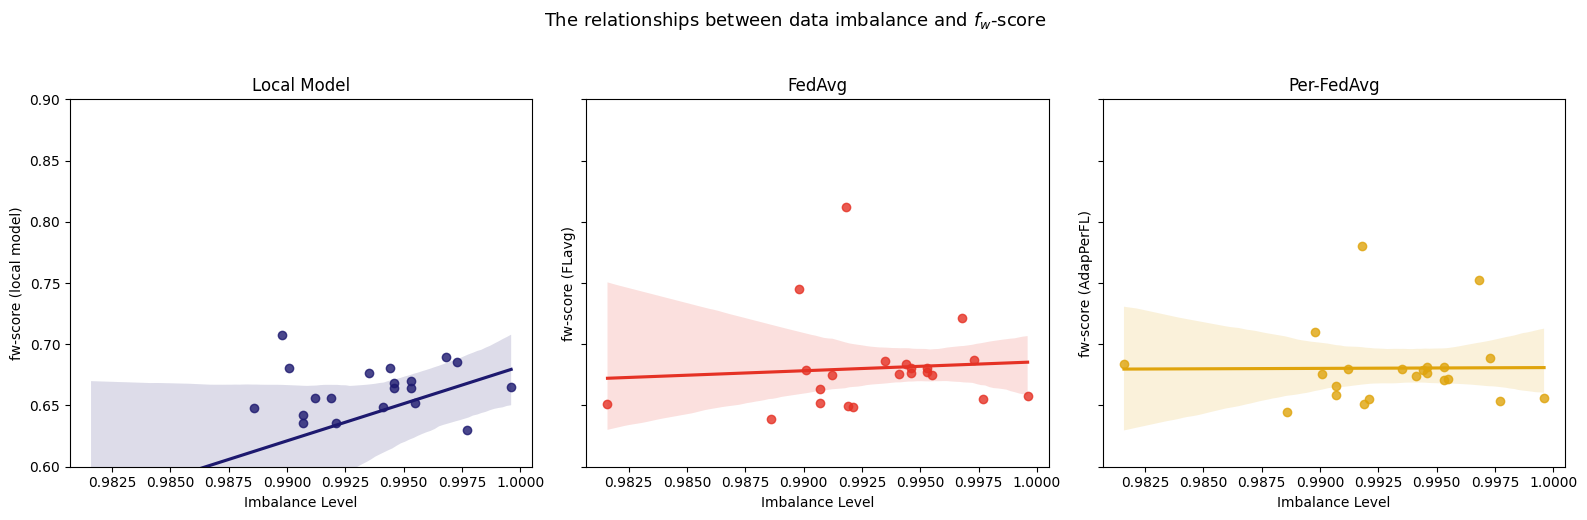

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Silo characteristics table (hardcoded from your table, Total row excluded)
silo_stats = pd.DataFrame({
    'Silo': ['Southeast Asia', 'South Asia', 'Oceania', 'Eastern Asia', 'West Asia',
              'West of USA', 'US Center', 'West Africa', 'Central Africa', 'North Africa',
              'Western Europe', 'Northern Europe', 'Central America', 'Caribbean',
              'South America', 'East Africa', 'Southern Europe', 'East of USA', 'Canada',
              'Southern Africa', 'Central Asia', 'Eastern Europe', 'South of USA'],
    'Imbalance': [0.9912, 0.9886, 0.9953, 0.9946, 0.9919, 0.9955, 0.9921, 0.9977, 0.9816,
                  0.9941, 0.9901, 0.9953, 0.9935, 0.9973, 0.9946, 0.9898, 0.9944, 0.9907,
                  0.9996, 0.9968, 0.9918, 0.9907, 0.9904],
})

# Merge with each model's Fw scores (expects local_df, fedavg_df, perfedavg_df
# already built, each with columns 'Silo' and 'Fw' -- see earlier scripts)
data_local = silo_stats.merge(local_df[['Silo', 'Fw']], on='Silo')
data_fedavg = silo_stats.merge(fedavg_df[['Silo', 'Fw']], on='Silo')
data_perfed = silo_stats.merge(perfedavg_df[['Silo', 'Fw']], on='Silo')

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

sns.regplot(data=data_local, x='Imbalance', y='Fw', ax=axes[0],
            scatter_kws={'color': '#1d196f'}, line_kws={'color': '#1d196f'})
axes[0].set_title('Local Model')
axes[0].set_ylabel('fw-score (local model)')
axes[0].set_xlabel('Imbalance Level')

sns.regplot(data=data_fedavg, x='Imbalance', y='Fw', ax=axes[1],
            scatter_kws={'color': '#e53225'}, line_kws={'color': '#e53225'})
axes[1].set_title('FedAvg')
axes[1].set_ylabel('fw-score (FLavg)')
axes[1].set_xlabel('Imbalance Level')

sns.regplot(data=data_perfed, x='Imbalance', y='Fw', ax=axes[2],
            scatter_kws={'color': '#dfa40c'}, line_kws={'color': '#dfa40c'})
axes[2].set_title('Per-FedAvg')
axes[2].set_ylabel('fw-score (AdapPerFL)')
axes[2].set_xlabel('Imbalance Level')

for ax in axes:
    ax.set_ylim(0.60, 0.90)

fig.suptitle('The relationships between data imbalance and $f_w$-score', y=1.03, fontsize=13)
plt.tight_layout()
plt.savefig('imbalance_vs_fw.png', dpi=200, bbox_inches='tight')
plt.show()


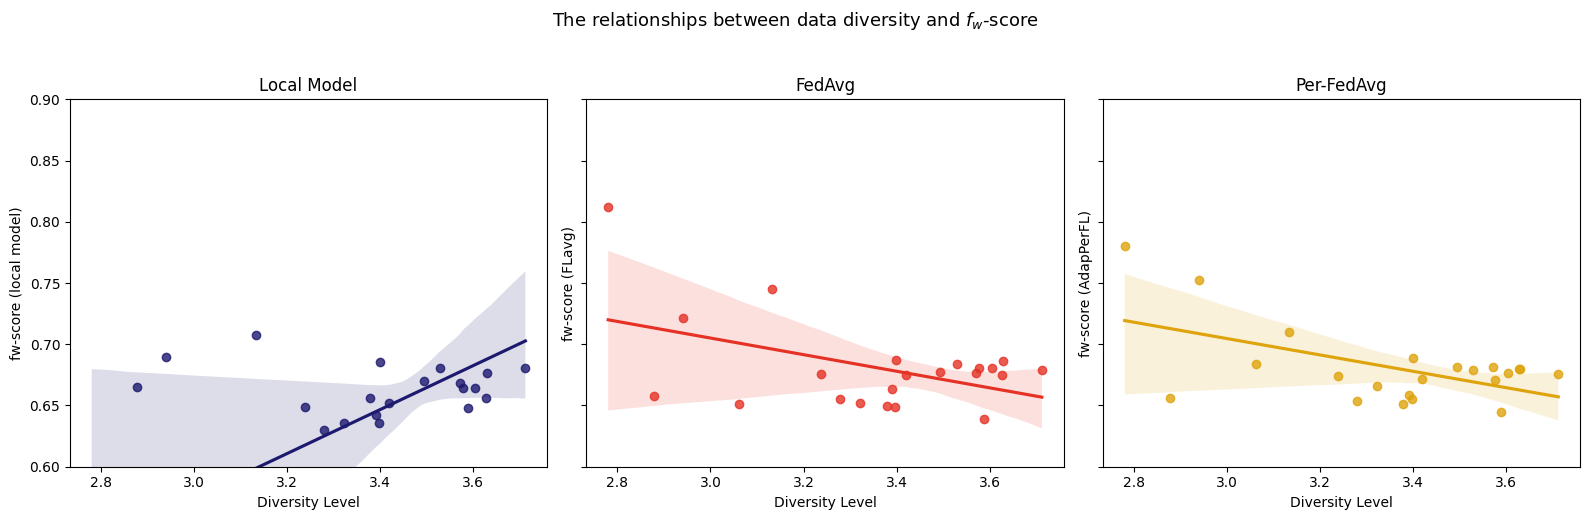

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Silo characteristics table (hardcoded from your table, Total row excluded)
silo_stats = pd.DataFrame({
    'Silo': ['Southeast Asia', 'South Asia', 'Oceania', 'Eastern Asia', 'West Asia',
              'West of USA', 'US Center', 'West Africa', 'Central Africa', 'North Africa',
              'Western Europe', 'Northern Europe', 'Central America', 'Caribbean',
              'South America', 'East Africa', 'Southern Europe', 'East of USA', 'Canada',
              'Southern Africa', 'Central Asia', 'Eastern Europe', 'South of USA'],
    'Diversity': [3.6272, 3.5879, 3.5770, 3.6047, 3.3791, 3.4192, 3.3970, 3.2784, 3.0615,
                  3.2385, 3.7121, 3.4936, 3.6289, 3.3988, 3.5707, 3.1331, 3.5288, 3.3905,
                  2.8785, 2.9405, 2.7801, 3.3214, 3.3266],
})

# Merge with each model's Fw scores (expects local_df, fedavg_df, perfedavg_df
# already built, each with columns 'Silo' and 'Fw' -- see earlier scripts)
data_local = silo_stats.merge(local_df[['Silo', 'Fw']], on='Silo')
data_fedavg = silo_stats.merge(fedavg_df[['Silo', 'Fw']], on='Silo')
data_perfed = silo_stats.merge(perfedavg_df[['Silo', 'Fw']], on='Silo')

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

sns.regplot(data=data_local, x='Diversity', y='Fw', ax=axes[0],
            scatter_kws={'color': '#1d196f'}, line_kws={'color': '#1d196f'})
axes[0].set_title('Local Model')
axes[0].set_ylabel('fw-score (local model)')
axes[0].set_xlabel('Diversity Level')

sns.regplot(data=data_fedavg, x='Diversity', y='Fw', ax=axes[1],
            scatter_kws={'color': '#e53225'}, line_kws={'color': '#e53225'})
axes[1].set_title('FedAvg')
axes[1].set_ylabel('fw-score (FLavg)')
axes[1].set_xlabel('Diversity Level')

sns.regplot(data=data_perfed, x='Diversity', y='Fw', ax=axes[2],
            scatter_kws={'color': '#dfa40c'}, line_kws={'color': '#dfa40c'})
axes[2].set_title('Per-FedAvg')
axes[2].set_ylabel('fw-score (AdapPerFL)')
axes[2].set_xlabel('Diversity Level')

for ax in axes:
    ax.set_ylim(0.60, 0.90)

fig.suptitle('The relationships between data diversity and $f_w$-score', y=1.03, fontsize=13)
plt.tight_layout()
plt.savefig('diversity_vs_fw.png', dpi=200, bbox_inches='tight')
plt.show()